# Itô integral and Itô formula

The left-endpoint Itô sum is not an ordinary Riemann integral. For
$f(W_t)=W_t^2$, Itô formula predicts
$W_t^2=2\int_0^t W_s\,dW_s+t$.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Convergence experiment

Independent ensembles are simulated at several time-step sizes. For each path,
the left-endpoint sum approximates $\int W\,dW$. The RMS discrepancy from
Itô formula is measured at the final time.


In [2]:
rng = np.random.default_rng(62704)
final_time = 1.0
path_count = 10_000
step_counts = 2 ** np.arange(4, 11)
rms_error = np.zeros(step_counts.size)

for index, step_count in enumerate(step_counts):
    time_step = final_time / step_count
    wiener_value = np.zeros(path_count)
    ito_integral = np.zeros(path_count)
    for _ in range(step_count):
        increment = np.sqrt(time_step) * rng.standard_normal(path_count)
        ito_integral += wiener_value * increment
        wiener_value += increment
    residual = wiener_value**2 - 2.0 * ito_integral - final_time
    rms_error[index] = np.sqrt(np.mean(residual**2))

illustration_step_count = 512
illustration_dt = final_time / illustration_step_count
illustration_increment = np.sqrt(illustration_dt) * rng.standard_normal(
    illustration_step_count
)
illustration_w = np.concatenate(([0.0], np.cumsum(illustration_increment)))
illustration_integral = np.concatenate((
    [0.0],
    np.cumsum(illustration_w[:-1] * illustration_increment),
))
illustration_time = np.linspace(0.0, final_time, illustration_step_count + 1)


## Verification

The residual is controlled by the error in quadratic variation and should
decrease approximately as $\Delta t^{1/2}$.


In [3]:
step_sizes = final_time / step_counts
convergence_slope = np.polyfit(
    np.log(step_sizes), np.log(rms_error), 1
)[0]
assert 0.42 < convergence_slope < 0.58
assert rms_error[-1] < 0.06
print(f"RMS convergence slope = {convergence_slope:.4f}")
print(f"finest RMS residual = {rms_error[-1]:.6f}")


RMS convergence slope = 0.4992
finest RMS residual = 0.044247


## Instructive plot

The first panel shows one nondifferentiable path. The second verifies the Itô
correction along that path. The third establishes the expected convergence
rate over an ensemble.


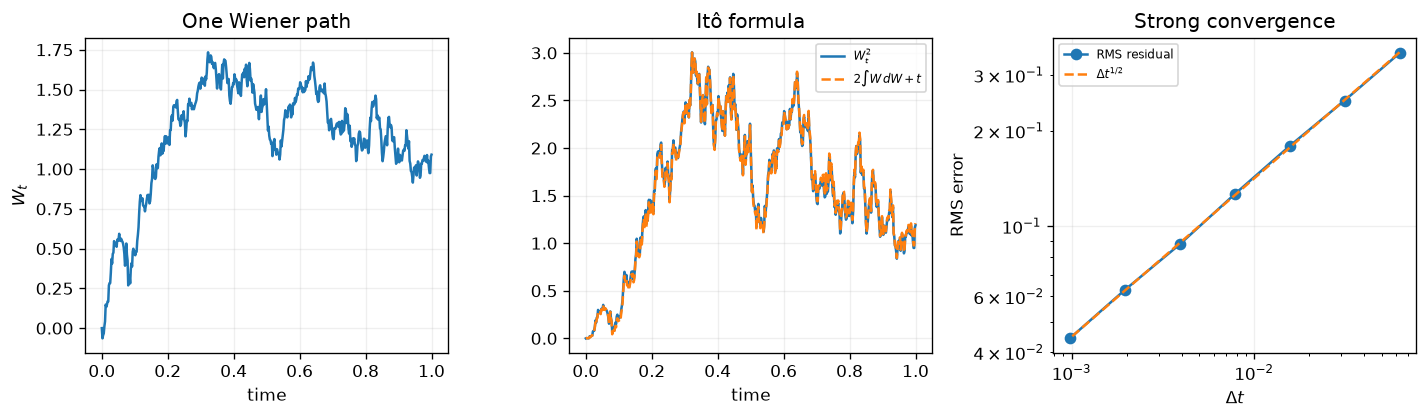

wrote lecture-notes/figures/08_brownian-motion-diffusion/04-ito-integral-and-formula.pdf


In [4]:
figure, axes = plt.subplots(1, 3, figsize=(12.0, 3.6))

axes[0].plot(illustration_time, illustration_w)
axes[0].set(title="One Wiener path", xlabel="time", ylabel=r"$W_t$")

axes[1].plot(illustration_time, illustration_w**2, label=r"$W_t^2$")
axes[1].plot(
    illustration_time,
    2.0 * illustration_integral + illustration_time,
    "--",
    label=r"$2\int W\,dW+t$",
)
axes[1].set(title="Itô formula", xlabel="time")
axes[1].legend(fontsize=7)

axes[2].loglog(step_sizes, rms_error, "o-", label="RMS residual")
reference = rms_error[-1] * np.sqrt(step_sizes / step_sizes[-1])
axes[2].loglog(step_sizes, reference, "--", label=r"$\Delta t^{1/2}$")
axes[2].set(title="Strong convergence", xlabel=r"$\Delta t$", ylabel="RMS error")
axes[2].legend(fontsize=7)

for axis in axes:
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "04-ito-integral-and-formula.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
